<a href="https://colab.research.google.com/github/zijierongjay/MSSP607/blob/main/Modules/Week_7/Untitled9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import userdata
import subprocess

github_token = userdata.get('Git_Key')

owner = 'zijierongjay'
repository = 'MSSP607'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

subprocess.run(
    ['git', 'clone', clone_url],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

print("Repository cloned successfully.")

Repository cloned successfully.


In [5]:
import os

os.listdir('/content')

['.config', 'MSSP607', 'sample_data']

In [6]:
import os

os.chdir('/content/MSSP607')

print(os.getcwd())

/content/MSSP607


In [7]:
os.listdir('Modules/Week_7')

['InternetSales.csv', '.gitkeep']

In [9]:
import pandas as pd

df = pd.read_csv(
    'Modules/Week_7/InternetSales.csv',
    encoding='latin1'
)

df.head()

/tmp/ipykernel_2763/3180061933.py:3: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [10]:
df.columns

Index(['ID', 'CustomerKey', 'GeographyKey', 'City', 'CountryRegionCode',
       'EnglishCountryRegionName', 'CustomerAlternateKey', 'Title',
       'FirstName', 'MiddleName', 'LastName', 'NameStyle', 'BirthDate',
       'MaritalStatus', 'Suffix', 'Gender', 'EmailAddress', 'YearlyIncome',
       'TotalChildren', 'NumberChildrenAtHome', 'EnglishEducation',
       'SpanishEducation', 'FrenchEducation', 'EnglishOccupation',
       'SpanishOccupation', 'FrenchOccupation', 'HouseOwnerFlag',
       'NumberCarsOwned', 'AddressLine1', 'AddressLine2', 'Phone',
       'DateFirstPurchase', 'CommuteDistance', 'ProductKey',
       'EnglishProductName', 'OrderDateKey', 'DueDateKey', 'ShipDateKey',
       'CustomerKey.1', 'PromotionKey', 'CurrencyKey', 'SalesTerritoryKey',
       'SalesOrderNumber', 'SalesOrderLineNumber', 'RevisionNumber',
       'OrderQuantity', 'UnitPrice', 'ExtendedAmount', 'UnitPriceDiscountPct',
       'DiscountAmount', 'ProductStandardCost', 'TotalProductCost',
       'SalesAmo

In [11]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

df['OrderDate'].head()

,OrderDate
0,2011-01-19
1,2013-01-18
2,2013-01-18
3,2013-05-03
4,2013-05-03


In [12]:
df['Year'] = df['OrderDate'].dt.year

df[['OrderDate', 'Year']].head()

,OrderDate,Year
0,2011-01-19,2011
1,2013-01-18,2013
2,2013-01-18,2013
3,2013-05-03,2013
4,2013-05-03,2013


In [13]:
yearly_sales = df.groupby('Year')['SalesAmount'].sum()

yearly_sales

,SalesAmount
Year,
2010,4.342104e+04
2011,7.075526e+06
2012,5.842485e+06
2013,1.635155e+07
2014,4.569472e+04


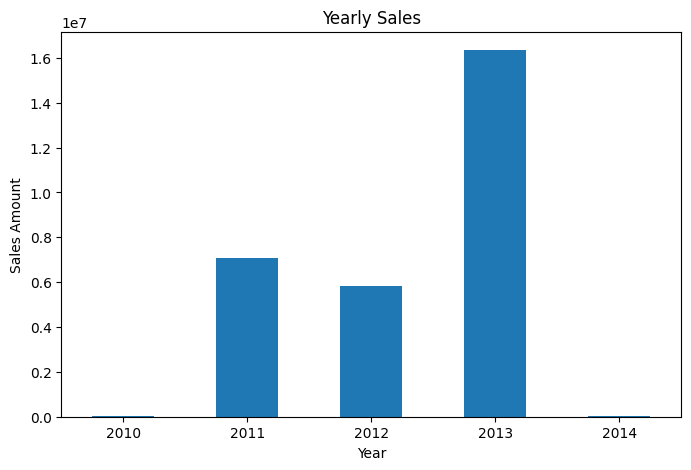

In [16]:
import matplotlib.pyplot as plt

yearly_sales.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Yearly Sales')
plt.xlabel('Year')
plt.ylabel('Sales Amount')
plt.xticks(rotation=0)

plt.savefig('yearly_sales.pdf', bbox_inches='tight')

plt.show()

In [17]:
import os

os.path.exists('yearly_sales.pdf')

True

In [18]:
from google.colab import files

files.download('yearly_sales.pdf')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>